# Home Credit Final Assignment Analysis
This notebook reproduces the data analysis, modeling, threshold selection, and financial-impact numbers used in the proposal deck.


## 1. Setup
Place the course/Kaggle CSV files in `data/`. If the file is missing, the notebook uses a tiny demo dataset so the code still runs, but demo results are not valid for submission.


In [2]:
import os, json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, RocCurveDisplay
warnings.filterwarnings('ignore')

def find_training_csv():
    candidates = [
        Path('data/application_train.csv'),
        Path('../data/application_train.csv'),
        Path('application_train.csv'),
        Path('../application_train.csv'),
        Path.home() / 'Downloads' / 'application_train.csv',
    ]
    for path in candidates:
        if path.exists():
            return path
    for folder in [Path.cwd(), Path.cwd() / 'data', Path.cwd().parent]:
        if folder.exists():
            for path in folder.glob('**/application_train.csv'):
                if '.venv' not in path.parts:
                    return path
    return None

def make_demo_dataset(n=1200, seed=42):
    rng = np.random.default_rng(seed)
    income = rng.lognormal(mean=11.7, sigma=0.55, size=n).clip(40000, 600000)
    credit = income * rng.uniform(1.2, 5.0, size=n)
    annuity = credit * rng.uniform(0.025, 0.07, size=n)
    ext = rng.beta(4, 2, size=n)
    risk = -2.0 + 1.2 * (annuity / income) + 1.1 * (credit / income > 3.2) - 2.0 * ext + rng.normal(0, 0.5, size=n)
    prob = 1 / (1 + np.exp(-risk))
    target = rng.binomial(1, prob)
    return pd.DataFrame({
        'SK_ID_CURR': np.arange(100000, 100000 + n),
        'TARGET': target,
        'AMT_INCOME_TOTAL': income,
        'AMT_CREDIT': credit,
        'AMT_ANNUITY': annuity,
        'EXT_SOURCE_2': ext,
        'NAME_CONTRACT_TYPE': rng.choice(['Cash loans', 'Revolving loans'], size=n, p=[0.85, 0.15]),
        'CODE_GENDER': rng.choice(['F', 'M'], size=n),
    })

TRAIN_PATH = find_training_csv()
DEMO_MODE = TRAIN_PATH is None


In [3]:
if DEMO_MODE:
    print('REAL DATA NOT FOUND: running on a small demo dataset only so the notebook code can execute.')
    print('For submission, download Home Credit Default Risk data and put application_train.csv in the data folder.')
    df = make_demo_dataset()
else:
    print(f'Using real data: {TRAIN_PATH}')
    df = pd.read_csv(TRAIN_PATH)
print(df.shape)
display(df.head())


REAL DATA NOT FOUND: running on a small demo dataset only so the notebook code can execute.
For submission, download Home Credit Default Risk data and put application_train.csv in the data folder.
(1200, 8)


,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,EXT_SOURCE_2,NAME_CONTRACT_TYPE,CODE_GENDER
0,100000,0,142570.856523,283223.223518,14568.572154,0.655033,Cash loans,F
1,100001,0,68050.730418,190976.843759,10483.772970,0.563761,Cash loans,M
2,100002,0,182179.575411,340552.932609,15212.758967,0.910334,Cash loans,M
3,100003,0,202260.266287,346235.129890,20436.679652,0.716080,Cash loans,M
4,100004,0,41230.380165,184261.503224,12878.963785,0.626931,Cash loans,F


## 2. Dataset Overview And EDA


In [4]:
target_rate = df['TARGET'].mean()
print(f'Rows: {len(df):,}')
print(f'Default / payment difficulty rate: {target_rate:.2%}')
missing = df.isna().mean().sort_values(ascending=False).head(20)
display(missing.to_frame('missing_rate'))


Rows: 1,200
Default / payment difficulty rate: 8.17%


,missing_rate
SK_ID_CURR,0.0
TARGET,0.0
AMT_INCOME_TOTAL,0.0
AMT_CREDIT,0.0
AMT_ANNUITY,0.0
EXT_SOURCE_2,0.0
NAME_CONTRACT_TYPE,0.0
CODE_GENDER,0.0


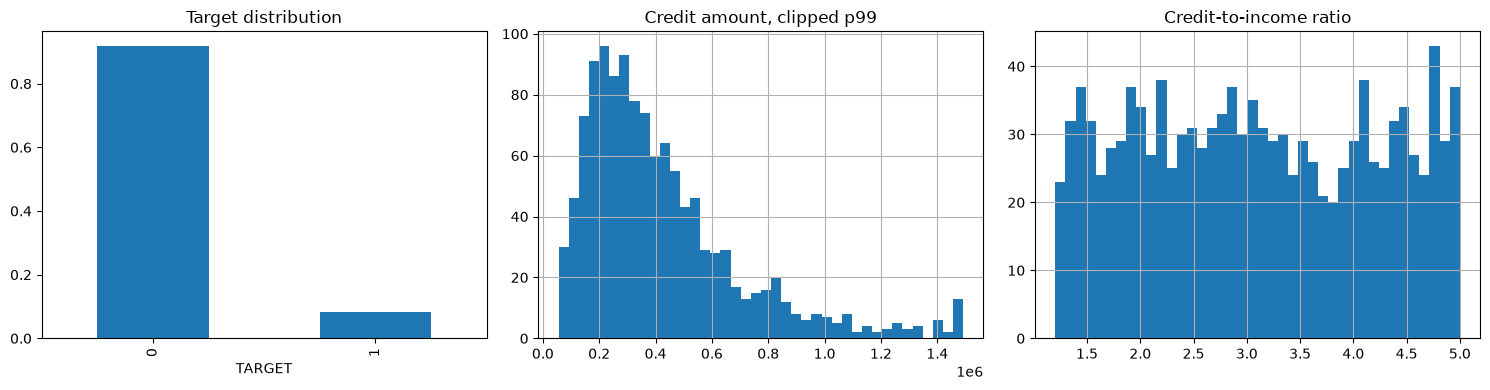

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['TARGET'].value_counts(normalize=True).sort_index().plot(kind='bar', ax=axes[0], title='Target distribution')
df['AMT_CREDIT'].clip(upper=df['AMT_CREDIT'].quantile(.99)).hist(ax=axes[1], bins=40)
axes[1].set_title('Credit amount, clipped p99')
if 'AMT_INCOME_TOTAL' in df.columns:
    (df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL'].replace(0, np.nan)).clip(upper=10).hist(ax=axes[2], bins=40)
    axes[2].set_title('Credit-to-income ratio')
plt.tight_layout()


## 3. Baseline Model
This baseline is intentionally simple and transparent. Add richer feature engineering or LightGBM/XGBoost if available.


Validation AUC: 0.5255


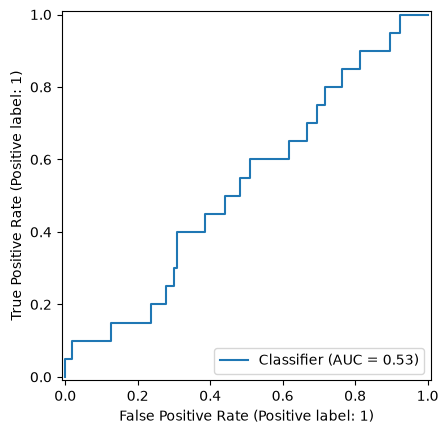

In [6]:
y = df['TARGET']
X = df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore')
num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()
preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=50))]), cat_cols),
])
model = Pipeline([
    ('preprocess', preprocess),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', n_jobs=None))
])
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
model.fit(X_train, y_train)
pred = model.predict_proba(X_valid)[:, 1]
auc = roc_auc_score(y_valid, pred)
print(f'Validation AUC: {auc:.4f}')
RocCurveDisplay.from_predictions(y_valid, pred)
plt.show()


## 4. Threshold And Business Simulation


In [7]:
valid = X_valid.copy()
valid['TARGET'] = y_valid.values
valid['pd_score'] = pred
LGD = 0.50  # loss-given-default assumption; replace with business assumption if provided
MARGIN_RATE = 0.10  # estimated interest/margin on non-defaulted exposure
exposure = valid.get('AMT_CREDIT', pd.Series(np.ones(len(valid)), index=valid.index)).fillna(valid.get('AMT_CREDIT', pd.Series([1])).median())
def profit_at_threshold(t):
    approve = valid['pd_score'] < t
    good_profit = ((valid['TARGET'] == 0) & approve) * exposure * MARGIN_RATE
    bad_loss = ((valid['TARGET'] == 1) & approve) * exposure * LGD
    return float(good_profit.sum() - bad_loss.sum()), int(approve.sum()), float(approve.mean())
rows = []
for t in np.linspace(0.02, 0.50, 49):
    p, n, r = profit_at_threshold(t)
    rows.append({'threshold': t, 'estimated_profit': p, 'approved_count': n, 'approval_rate': r})
sim = pd.DataFrame(rows).sort_values('estimated_profit', ascending=False)
display(sim.head(10))
best = sim.iloc[0]
print('Best threshold:', round(best.threshold, 3), 'Approval rate:', f'{best.approval_rate:.1%}')


,threshold,estimated_profit,approved_count,approval_rate
48,0.50,3.243914e+06,156,0.650000
47,0.49,2.998825e+06,153,0.637500
44,0.46,2.955504e+06,130,0.541667
46,0.48,2.857921e+06,142,0.591667
42,0.44,2.804056e+06,115,0.479167
43,0.45,2.763190e+06,119,0.495833
45,0.47,2.758248e+06,139,0.579167
41,0.43,2.500841e+06,106,0.441667
40,0.42,2.076675e+06,99,0.412500
39,0.41,2.013182e+06,97,0.404167


Best threshold: 0.5 Approval rate: 65.0%


## 5. Export Slide Metrics


In [8]:
metrics = {
    'rows': int(len(df)),
    'default_rate': float(target_rate),
    'validation_auc': float(auc),
    'best_threshold': float(best.threshold),
    'approval_rate': float(best.approval_rate),
    'estimated_profit': float(best.estimated_profit),
}
Path('../final_assignment_deliverables').mkdir(exist_ok=True)
with open('../final_assignment_deliverables/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
metrics


{'rows': 1200,
 'default_rate': 0.08166666666666667,
 'validation_auc': 0.5254545454545455,
 'best_threshold': 0.5,
 'approval_rate': 0.65,
 'estimated_profit': 3243913.5995715735}